# B5 — Qui tester en priorité ? Optimisation sur un graphe de contacts

**Problématique :** identifier exactement $k$ personnes sur un graphe de contacts pour maximiser une couverture combinatoire, puis évaluer l'intervention avec un modèle SIR. **Le verrou est l'optimisation, pas l'apprentissage d'un modèle IA.**

Plan : données → objectif et ILP → glouton et centralités → vérification indépendante → simulation SIR uniforme / pondérée → comparaison qualité/temps → limites médicales.

In [2]:
from pathlib import Path
import sys, math
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from src import data, selection, sir, verifier, plots
from src.run_experiments import run
print('Racine projet :', ROOT)


Racine projet : c:\CoursIA\2026-MSMIS5IN11-Search-Symbolic\groupe-b5


## 1 — Données de contacts SocioPatterns

Chaque ligne brute indique un contact de 20 s entre deux identifiants anonymes. Le graphe agrégé est **non orienté et pondéré** par le nombre d'intervalles de contact. Le graphe statique ne conserve pas l'ordre des événements.

Si les données hospitalières ne sont pas téléchargées, une démo **synthétique** fonctionne sans Internet. Les conclusions de l'oral doivent distinguer sans ambiguïté synthétique et réel.

In [3]:
# Chargement du graphe 
# On cherche d'abord le fichier .dat.gz, puis, à défaut, le .csv.zip (deux formats de la même source)
path = ROOT / 'data/raw/hospital.dat.gz'
if not path.exists():
    path = ROOT / 'data/raw/hospital.csv.zip'
if path.exists():
    G = data.load_graph(path)
    source = f'SocioPatterns réel : {path.name}'
else:
    # Aucune donnée réelle : graphe aléatoire de démonstration (3 groupes de 15 personnes).
    # L'étiquette 'source' rappelle que les résultats ne sont alors pas à interpréter médicalement.
    G = data.synthetic_graph(n_groups=3, group_size=15, seed=0)
    source = 'SYNTHÉTIQUE (démo seulement)'
print(source, '| personnes :', G.number_of_nodes(), '| contacts distincts :', G.number_of_edges())
# somme des durées de tous les contacts : sert de dénominateur pour les pourcentages de contacts coupés
print('Poids total des contacts :', selection.total_weight(G))

SocioPatterns réel : hospital.dat.gz | personnes : 75 | contacts distincts : 1139
Poids total des contacts : 32424


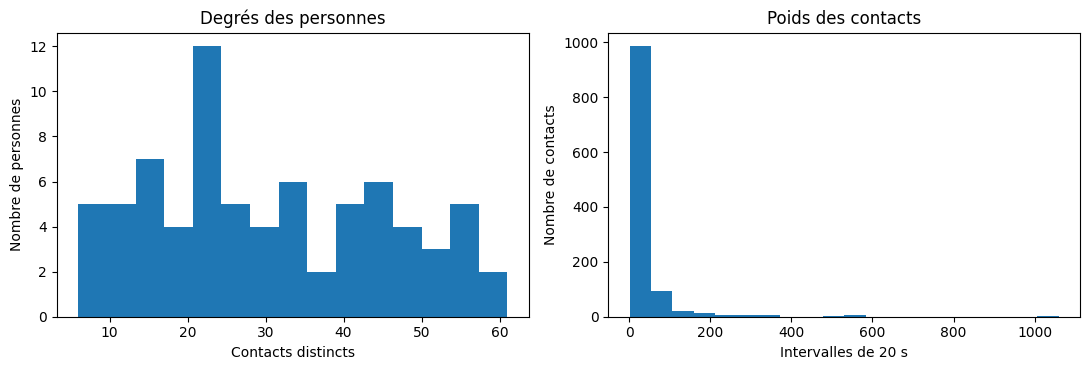

In [4]:

# --- Aperçu de la structure du graphe : deux histogrammes côte à côte ---
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
# gauche : combien de contacts distincts a chaque personne (distribution des degrés)
ax[0].hist([d for _, d in G.degree()], bins=15)
ax[0].set(title='Degrés des personnes', xlabel='Contacts distincts', ylabel='Nombre de personnes')
# droite : durée cumulée de chaque contact, en intervalles de 20 s (poids des arêtes)
ax[1].hist([d['weight'] for _, _, d in G.edges(data=True)], bins=20)
ax[1].set(title='Poids des contacts', xlabel='Intervalles de 20 s', ylabel='Nombre de contacts')
plt.tight_layout(); plt.show()

## 2 — Formulation combinatoire et ILP

Avec $S\subseteq V$, $|S|=k$, la **couverture de voisinage fermé** est :

$$f(S)=\left|\bigcup_{v\in S}\left(\{v\}\cup N(v)\right)\right|.$$

ILP : $x_i\in\{0,1\}$ cible $i$ ; $y_j\in[0,1]$ couvre $j$.

$$\max\sum_j y_j,\qquad y_j\le\sum_{i\in N[j]}x_i,\qquad \sum_i x_i=k.$$

**Extension V1 :** optimiser le poids des contacts coupés (arêtes incidentes, comptées une seule fois). Le glouton bénéficie de la garantie $1-1/e\approx 0,632$ pour ces deux **objectifs monotones sous-modulaires** ; cela ne garantit **pas** un gain SIR de 63 %.

In [5]:
# --- Application de toutes les méthodes de sélection ---
# k = 5 personnes à cibler (ou moins si le graphe est plus petit)
k = min(5, len(G))
# nom de la méthode -> fonction de sélection ; toutes prennent (G, k) et rendent une liste de personnes
methods = {'degree': selection.select_degree,
           'closeness': selection.select_closeness,
           'kcore': selection.select_kcore,
           'greedy': selection.select_greedy_coverage,
           'ilp': selection.select_ilp_coverage,
           'ilp_deg': selection.select_ilp_degree,
           'greedy_edges': selection.select_greedy_edges,
           'ilp_edges': selection.select_ilp_edges}
# on exécute chaque méthode : {nom: liste des k personnes choisies}
selections = {name: fun(G, k) for name, fun in methods.items()}
# tableau récapitulatif : pour chaque sélection, les deux objectifs mesurés
# (couverture des voisinages, poids des contacts coupés), et non seulement celui qu'elle optimise
scores = pd.DataFrame([{'méthode': key, 'personnes ciblées': len(s),
                        'couverture': selection.coverage(G,s),
                        'contacts coupés': round(selection.cut_weight(G,s),1)}
                       for key,s in selections.items()])
display(scores.sort_values('couverture', ascending=False))


,méthode,personnes ciblées,couverture,contacts coupés
3,greedy,5,75,10903
4,ilp,5,75,6839
5,ilp_deg,5,75,11168
0,degree,5,73,11957
1,closeness,5,73,11957
2,kcore,5,70,15323
6,greedy_edges,5,70,15323
7,ilp_edges,5,70,15323


## 3 — Qualité des solutions : vérificateur indépendant

L'ILP prouve l'optimum lorsqu'il retourne `optimal=True`. Le vérificateur n'utilise **ni NetworkX, ni le solveur, ni le code de sélection** ; il compare la taille k, l'existence et l'unicité des nœuds et recalcule les métriques. Sur de petits graphes, il vérifie aussi l'optimalité par énumération.

In [6]:
# --- Vérification indépendante des sélections ---
from tempfile import TemporaryDirectory
import json
# Dossier temporaire supprimé automatiquement à la sortie du bloc `with`
with TemporaryDirectory() as tmp:
    graph_file = Path(tmp)/'graph.json'; solutions_dir=Path(tmp)/'solutions'; solutions_dir.mkdir()
    # le vérificateur relit le graphe depuis un fichier JSON, comme en usage réel
    data.save_graph_json(G,graph_file)
    # une solution JSON par méthode, au format attendu par le vérificateur
    for name,s in selections.items():
        (solutions_dir/f'{name}.json').write_text(json.dumps({
            'method':name, 'k':k, 'selected':sorted(int(x) for x in s),   # int() : JSON n'accepte pas les types numpy
            'coverage':selection.coverage(G,s), 'cut_weight':selection.cut_weight(G,s),
            # objectif revendiqué : "cut_weight" pour les méthodes sur les contacts, "coverage" sinon
            'objective':'cut_weight' if name in ('greedy_edges','ilp_edges') else 'coverage',
            # optimal=None : on ne prétend pas ici que la sélection est optimale (champ présent car
            # le mode strict l'exige, mais sans affirmation à vérifier par force brute)
            'optimal':None}),encoding='utf-8')
    # strict=True : les champs de métriques sont obligatoires ; verify renvoie le nombre de
    # solutions fausses, donc l'assertion échoue si l'une d'elles est incorrecte
    assert verifier.verify(graph_file,solutions_dir,strict=True)==0


[OK]     closeness.json
[OK]     degree.json
[OK]     greedy.json
[OK]     greedy_edges.json
[OK]     ilp.json
[OK]     ilp_deg.json
[OK]     ilp_edges.json
[OK]     kcore.json

8/8 solutions valides


## 4 — Le SIR est une évaluation, pas l'optimiseur

- `uniform` : $P(i\to j)=\beta$ par pas si contact présent.
- `weighted` (fusion de V2) : $P(i\to j)=1-\exp(-\beta w_{ij}/\bar w)$.
- `gamma` : chance de guérison par pas ; les cibles sont **immunisées de manière idéale**.
- `seed_policy='fixed'` : mêmes candidats initiaux aléatoires pour toutes les méthodes (une personne déjà immunisée ne devient pas infectée).

Le scénario pondéré est **une hypothèse** de relation durée-risque et ne modélise pas une vraie action de dépistage. Pour un changement de scénario, recalibrer `beta` ou documenter les taux d'attaque de référence.

In [7]:
# --- Évaluation des sélections par simulation SIR ---
p = sir.prepare(G)   # prépare le graphe pour la simulation (structure interne réutilisée à chaque appel)
beta = 0.025  # taux de transmission : valeur de démonstration, pas une valeur clinique
rows=[]
for mode in ('uniform', 'weighted'):
    # Référence sans intervention (liste de cibles vide), pour ce mode de transmission.
    # base_seed fixe + seed_policy='fixed' : mêmes tirages pour toutes les méthodes => comparaison équitable
    baseline = sir.evaluate(p, [], beta=beta, gamma=0.2, n_runs=40,
                            n_seeds=3, base_seed=42, transmission=mode, seed_policy='fixed')
    # on compare quatre méthodes représentatives (une par famille)
    for method in ('degree','greedy','ilp','greedy_edges'):
        r = sir.evaluate(p, selections[method], beta=beta, gamma=0.2, n_runs=40,
                         n_seeds=3, base_seed=42, transmission=mode, seed_policy='fixed')
        rows.append({'SIR':mode, 'méthode':method, 'taux SIR':r['mean'],
                     'sans intervention':baseline['mean'],
                     # réduction relative du taux d'attaque vs sans intervention
                     # (le "if" évite une division par zéro si la référence est nulle)
                     'réduction %':100*(1-r['mean']/baseline['mean']) if baseline['mean'] else 0})
display(pd.DataFrame(rows).round(3))
print('Illustration pédagogique : 40 répétitions seulement, mêmes paramètres beta/gamma.')

,SIR,méthode,taux SIR,sans intervention,réduction %
0,uniform,degree,0.819,0.902,9.168
1,uniform,greedy,0.805,0.902,10.721
2,uniform,ilp,0.822,0.902,8.799
3,uniform,greedy_edges,0.812,0.902,9.908
4,weighted,degree,0.565,0.681,16.993
5,weighted,greedy,0.558,0.681,18.071
6,weighted,ilp,0.557,0.681,18.119
7,weighted,greedy_edges,0.525,0.681,22.821


Illustration pédagogique : 40 répétitions seulement, mêmes paramètres beta/gamma.


## 5 — Résultats réels exploratoires, reproduits par le programme CLI

Ces graphiques et CSV ont été produits sur les données réelles (hôpital et école primaire). Leur configuration exacte est conservée dans `results/examples/<scénario>/config.json`. Les observations servent à identifier des mécanismes, pas à annoncer une preuve clinique. **Il faut relancer davantage de simulations avant le rendu final**.

,method,coverage_pct,cut_pct,attack_mean,reduction_pct,time_s,optimal
24,random,95.867,27.714,0.641,21.369,0.000,NaN
25,degree,98.667,63.317,0.419,48.561,0.000,NaN
26,betweenness,98.667,60.162,0.448,45.011,0.022,NaN
27,pagerank,98.667,63.317,0.419,48.561,0.002,NaN
28,closeness,98.667,63.317,0.419,48.561,0.002,NaN
29,kcore,97.333,70.235,0.464,43.090,0.001,NaN
30,greedy,100.000,59.993,0.464,43.122,0.002,NaN
31,ilp,100.000,23.029,0.639,21.573,0.018,True
32,ilp_deg,100.000,61.757,0.452,44.553,0.019,True
33,strength,97.333,70.235,0.464,43.090,0.000,NaN


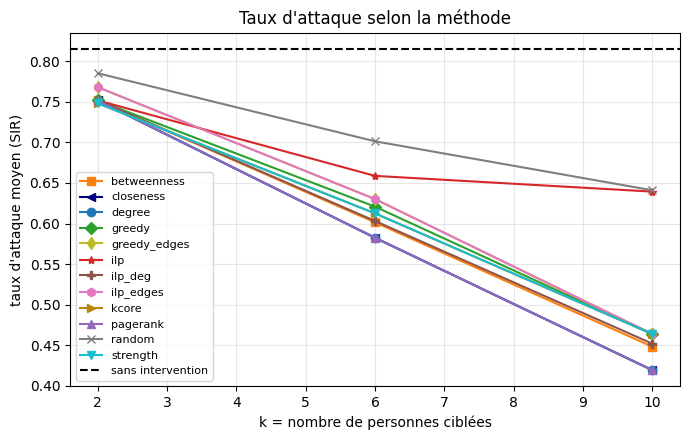

In [8]:
# --- Résultats pré-calculés par le programme en ligne de commande ---
folder = ROOT / 'results/examples/hospital_uniform_final'
if (folder/'results.csv').exists():
    df = pd.read_csv(folder/'results.csv')
    # on n'affiche que la ligne du plus grand k testé, pour chaque méthode
    display(df[df.k==df.k.max()][['method','coverage_pct','cut_pct','attack_mean','reduction_pct','time_s','optimal']].round(3))
    # Courbe du taux d'attaque selon k, avec la ligne de référence "sans intervention" lue dans
    # config.json ; à défaut de ce fichier, la référence est mise à 0.0
    # (`_ =` : on ignore la figure renvoyée, elle s'affiche via plt.show())
    _ = plots.plot_attack_rate(df, 0.0 if not (folder/'config.json').exists() else
        json.loads((folder/'config.json').read_text())['baseline']['mean'])
    plt.show()
else:
    print('Exemples non trouvés : lancer les commandes dans le README.') 


## 6 — Conclusion et discussion

**Message scientifique :** une couverture combinatoire ILP optimale ne signifie pas une meilleure diminution des infections SIR : les objectifs sont des **proxys** différents. Le départage par degré peut changer le taux SIR tout en gardant la couverture optimale. Le scénario SIR pondéré peut aussi reclasser les meilleures méthodes.

**Limites cliniques :** vaccination/isolement parfaits, pas de faux négatifs, pas de délais de test, pas de réseau temporel, pas de validation externe. **Limites numériques :** bruit Monte-Carlo, ILP exponentiel dans le pire cas, paramètres calibrés pour une hypothèse donnée.

**Travaux futurs :** coûts variables, temporalité des contacts, dépistage réaliste avec résultats différés, plus de répétitions et sensibilité des paramètres.